# Multiscale Organization in Sequence Representations - Learning Encodes Biochemical Properties

To determine if the model internalized fundamental biochemical knowledge, the authors projected the weights of the final embedding layer whos job it is to map the final hidden representation into one of the 25 amino acid classes, into two dimensions using t-SNE.

In [1]:
import esm
import pandas as pd
import numpy as np
import torch
import os
import random
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Reproducibility

In [2]:
SEED = 42
def set_seed(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(SEED)
print(f"Seed set to {SEED}. Ready to run.")

Seed set to 42. Ready to run.


# Load Model

Unfortunately the 36 Layer Transformer which was not avaivable in any released pypi version of the esm package so we had to resort to either esm1_t34_670M_UR100, esm1_t34_670M_UR50D, esm1_t34_670M_UR50S of which we chose the esm1_t34_670M_UR100 model.

In [3]:
model, alphabet = esm.pretrained.esm1_t34_670M_UR100()

if torch.cuda.is_available():
    model = model.cuda()
    print("Modell auf GPU geladen.")
model.eval()

print(model)

ProteinBertModel(
  (embed_tokens): Embedding(35, 1280, padding_idx=1)
  (layers): ModuleList(
    (0-33): 34 x TransformerLayer(
      (self_attn): MultiheadAttention(
        (k_proj): Linear(in_features=1280, out_features=1280, bias=True)
        (v_proj): Linear(in_features=1280, out_features=1280, bias=True)
        (q_proj): Linear(in_features=1280, out_features=1280, bias=True)
        (out_proj): Linear(in_features=1280, out_features=1280, bias=True)
      )
      (self_attn_layer_norm): ESM1LayerNorm()
      (fc1): Linear(in_features=1280, out_features=5120, bias=True)
      (fc2): Linear(in_features=5120, out_features=1280, bias=True)
      (final_layer_norm): ESM1LayerNorm()
    )
  )
  (contact_head): ContactPredictionHead(
    (regression): Linear(in_features=680, out_features=1, bias=True)
    (activation): Sigmoid()
  )
  (embed_positions): SinusoidalPositionalEmbedding()
)


# Define Properties

Here we just used the same Amino acids and Properties which they used in the paper

In [4]:
# The 20 standard amino acids used in Figure 1 of the paper
standard_aas = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 
                'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']

# Biochemical properties as defined in Figure 1 of the paper
aa_properties = {
    'Hydrophobic': ['M', 'L', 'I', 'V', 'A'],
    'Aromatic': ['F', 'W', 'Y'],
    'Polar': ['N', 'Q', 'S', 'T'],
    'Positively Charged': ['R', 'K', 'H'],
    'Negatively Charged': ['D', 'E'],
    'Unique': ['G', 'P', 'C', ]
}

# Visualization styles (colors and markers) (is there a better way to do this? where all have markers which would have the same bounding box size since eg. s is naturally larger than o)
group_styles = {
    'Hydrophobic': {'color': 'green', 'marker': 'o'},
    'Aromatic': {'color': 'forestgreen', 'marker': '+'},
    'Polar': {'color': 'blue', 'marker': 'o'},
    'Positively Charged': {'color': 'red', 'marker': 's'},
    'Negatively Charged': {'color': 'red', 'marker': 'x'},
    'Unique': {'color': 'orange', 'marker': 'o'}
}

size_mapping = {
    "Small (<120 Da)": ["T", 'S', 'A', "P", "G", 'V'],
    "Medium (120 - 150 Da)": ['C','M', "L",'I', 'N','D','E','Q','K'],
    "Large (> 150 Da)": ['R', 'H', 'F', 'W', 'Y']
}

size_values = {
    "Small (<120 Da)": 100,
    "Medium (120 - 150 Da)": 350,
    "Large (> 150 Da)": 600
}

aa_size_lookup = {}
for label, aas in size_mapping.items():
    for aa in aas:
        aa_size_lookup[aa] = size_values[label]

# Extract project the weight matrix of the final embedding layer of the network

Here it is important to mention, that the embedding weights of the input and output layer are shared, a detail which is never mentioned in the paper directly but is true since as we can see from the above output there is only one embedding layer

In [5]:
# 1. Determine the device from the model parameters
device = next(model.parameters()).device
print(f"Model is on device: {device}")

# 2. Get indices for standard amino acids
indices = [alphabet.get_idx(aa) for aa in standard_aas]
indices_tensor = torch.tensor(indices, device=device)

# 3. Extract the static embedding weights
# We use embed_tokens directly as this represents the learned "identity" of each AA
with torch.no_grad():
    embeddings = model.embed_tokens.weight[indices_tensor].cpu().numpy()

print(f"Extracted embeddings shape: {embeddings.shape}") 
# Expected Output: (20, 1280)

Model is on device: cpu
Extracted embeddings shape: (20, 1280)


# T-SNE Calculation and Visualization

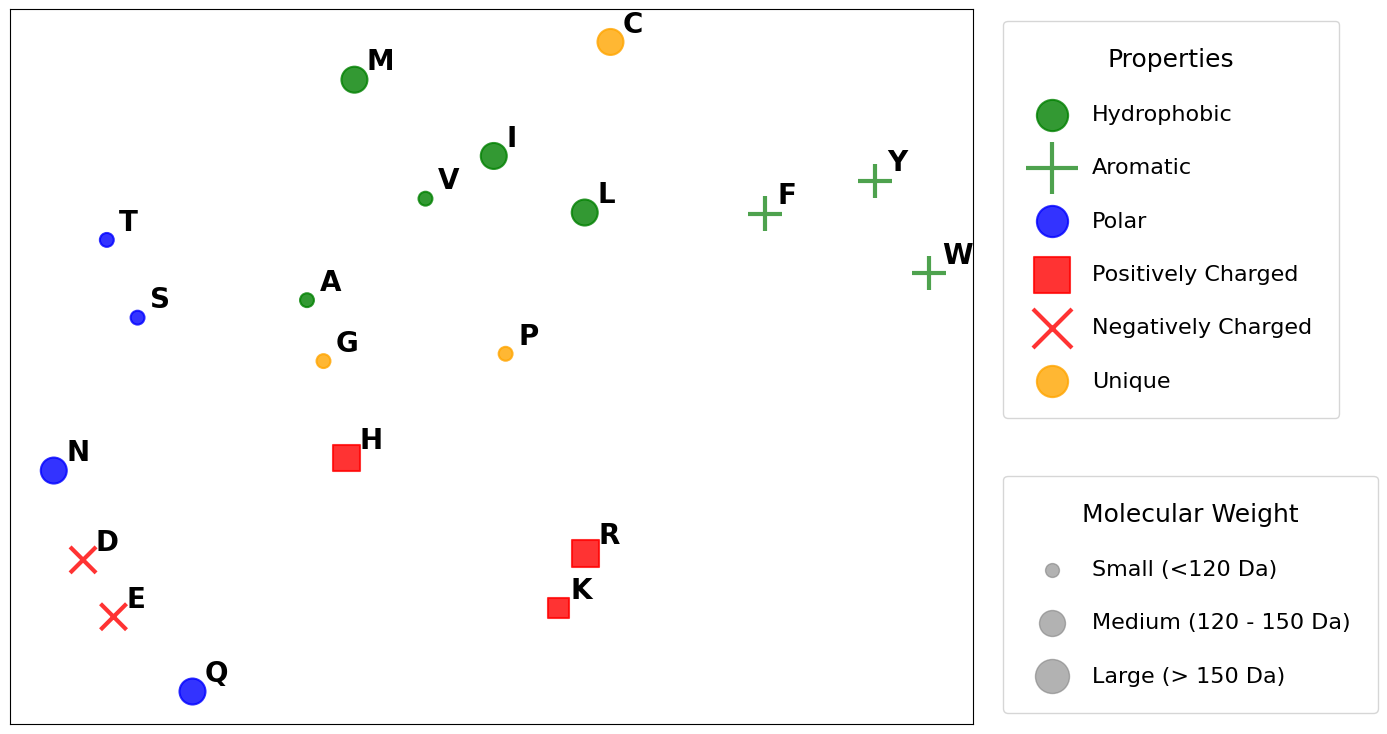

In [6]:
# 1. Compute t-SNE
tsne = TSNE(
    n_components=2, 
    perplexity=5,  
    random_state=42, 
    learning_rate='auto',
    # Removed n_iter to avoid TypeError in your version
)

embeddings_2d = tsne.fit_transform(embeddings)

# 3. Generate Plot
plt.figure(figsize=(14, 7.5)) 

# Plot each biochemical group
for label, aas in aa_properties.items():
    style = group_styles[label]
    
    # Get indices
    group_indices = [standard_aas.index(aa) for aa in aas]
    
    # Extract X and Y
    x = embeddings_2d[group_indices, 0]
    y = embeddings_2d[group_indices, 1]

    # Get base sizes from your lookup
    base_sizes = [aa_size_lookup[aa] for aa in aas]

    # Get Marker for Adjustment
    current_marker = style['marker']
    
    # Default linewidth
    lw = 1.5 
    
    # Start with base sizes
    final_sizes = base_sizes 
    
    # 1. Reduce square ('s') size so it doesn't look huge compared to circles
    if current_marker == 's':
        final_sizes = [s * 0.6 for s in base_sizes]
        
    # 2. Thicken lines for 'x' and '+' so they are visible
    elif current_marker in ['x', '+']:
        lw = 3.0  # Increased from default to make them bold
    
    # Scatter plot 
    plt.scatter(
        x, y, 
        c=style['color'], 
        marker=current_marker, 
        s=final_sizes, 
        label=label, 
        alpha=0.8, 
        linewidths=lw
    )
    
    # Annotate
    for i, idx in enumerate(group_indices):
        plt.annotate(standard_aas[idx], (x[i], y[i]), 
                     xytext=(9, 7), textcoords='offset points', 
                     fontsize=20, weight='bold')

# 4. Legends

# Top right Legend: Biochemical Properties
first_legend = plt.legend(
    bbox_to_anchor=(1.02, 1), 
    loc='upper left',
    title="Properties", 
    labelspacing=1.5, 
    borderpad=1.2,       
    fontsize=16,         
    title_fontsize=18,   
    markerscale=1.5      
)
plt.gca().add_artist(first_legend)

# Legend 2: Sizes
# Create "dummy" invisible points for the legend
size_handles = []
for size_label, size_val in size_values.items():
    handle = plt.scatter([], [], c='gray', alpha=0.6, s=size_val, label=size_label)
    size_handles.append(handle)

# Bottom right Legend: Molecular sizes
plt.legend(
    handles=size_handles, 
    bbox_to_anchor=(1.02, 0),
    loc='lower left',
    title="Molecular Weight", 
    labelspacing=1.5, 
    borderpad=1.2,
    fontsize=16,
    title_fontsize=18
)
# Final plot adjustments
plt.xticks([])
plt.yticks([])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()